# Annual divorce associations and observed profiles

## Findings

Annual outcomes are preferable to cumulative proportions for this comparison, but the at-risk population and marital exposure must also align. Recent ACS joint models show larger predefined unemployment and high-school/BA differences than an additional graduate degree. NLSY prospective person-time analysis does not confirm a universal protective religion/credential profile.

This is a reproducible results-and-validation companion to the full report. The source-fitting scripts and analytical datasets are adjacent; original earlier results are retained.


## Context and methods

ACS2023: ages30–64, one marriage to date, no marriage in the previous12months, approximate annual at-risk denominator. Joint degree/income/work/age-at-marriage/duration/contextual-race model, all80 survey replicates. Predicted annual proportions are not causal risks.

NLSY79: legally married or separated at an interval start, baseline predictors before follow-up, exact reported month exposure, cause-specific divorce incidence. Respondent-cluster approximate95% CIs omit full survey strata/PSUs. Follow-up2000–2022 in the1957–1964 cohort. Separation state is shown separately because conditioning on it changes the question.

### Key assumptions

Categorical ACS logit and NLSY log-linear rate specifications; no guaranteed causal identification or transport to new marriages. Income/work after divorce can distort ACS associations. NLSY missing follow-up/covariates selects its sample. These outputs cannot identify a single ideal spouse.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
import runpy
ROOT=Path.cwd()
assert (ROOT/'annual_acs/first_marriage/profiles.csv').exists()
contrasts=pd.read_csv(ROOT/'annual_acs/first_marriage/marginal_contrasts.csv')
profiles=pd.read_csv(ROOT/'annual_acs/first_marriage/profiles.csv')
prospective=pd.read_csv(ROOT/'annual_nlsy/legally_married_primary/annual_adjusted_without_separation_state.csv')


## Joint annual comparisons

These formal contrasts share a percentage-point scale within sex. Confidence intervals retain matched replicate covariance. “Largest” depends on which contrasts are specified; do not treat selected category ranges as universal variable importance.


,sex,factor,level,reference,estimate,ci95_low,ci95_high
8,Men,education,High school/GED,Bachelor,0.442,0.272,0.612
11,Men,education,Master,Bachelor,0.034,-0.146,0.214
18,Men,income_group,"100,000-149,999","50,000-74,999",-0.356,-0.537,-0.176
20,Men,income_group,"200,000+","50,000-74,999",-0.463,-0.645,-0.280
21,Men,employment,Unemployed,Employed,0.627,0.210,1.043
32,Women,education,High school/GED,Bachelor,0.607,0.454,0.761
35,Women,education,Master,Bachelor,-0.174,-0.312,-0.037
42,Women,income_group,"100,000-149,999","50,000-74,999",-0.085,-0.352,0.182
44,Women,income_group,"200,000+","50,000-74,999",-0.286,-0.633,0.062
45,Women,employment,Unemployed,Employed,1.091,0.597,1.586


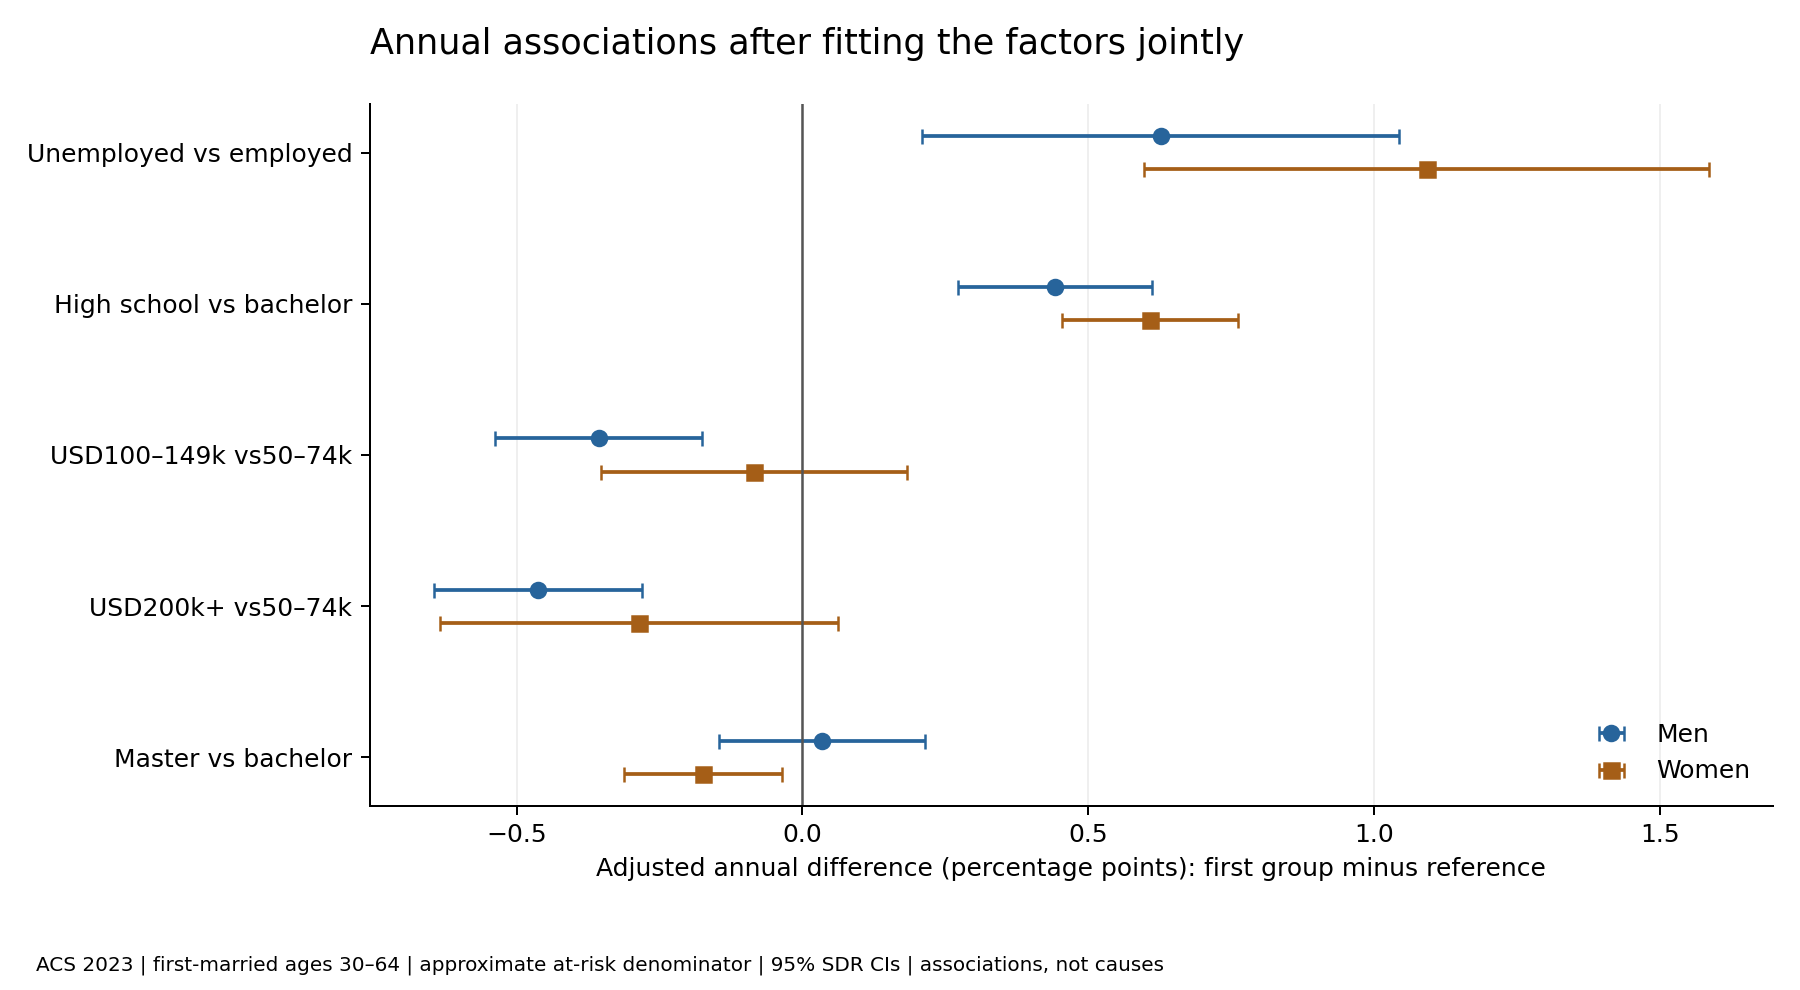

In [2]:
selected=contrasts[(contrasts.factor.isin(['education','employment','income_group'])) & contrasts.level.isin(['High school/GED','Master','Unemployed','100,000-149,999','200,000+'])]
display(selected[['sex','factor','level','reference','estimate','ci95_low','ci95_high']].round(3))
_ = runpy.run_path(str(ROOT/'plot_annual.py'),run_name='__main__')
display(Image(filename=str(ROOT.parent/'figures/annual_driver_contrasts.png')))


## Supported profiles and sample sizes

Profiles were specified rather than selected by minimizing fitted risk. Counts refer to observed joint settings; modeled estimates standardize over age-at-marriage, duration and race. Different sex-specific targets are not matched spouse comparisons.


In [3]:
display(profiles[['sex','profile','unweighted_n','unweighted_events','estimate','ci95_low','ci95_high']].round(3))
assert (profiles.unweighted_events>0).all()
assert ((profiles.ci95_low<=profiles.estimate)&(profiles.estimate<=profiles.ci95_high)).all()


,sex,profile,unweighted_n,unweighted_events,estimate,ci95_low,ci95_high
0,Men,Bachelor employed 50-74k once,13701,161,1.139,1.008,1.270
1,Men,Bachelor employed 100-149k once,20837,139,0.841,0.736,0.946
2,Men,Master employed 100-149k once,10443,76,0.867,0.703,1.031
3,Men,Bachelor employed 200k+ once,14872,76,0.752,0.634,0.871
4,Men,Master employed 200k+ once,10553,65,0.776,0.640,0.912
5,Men,Bachelor NILF zero income once,1766,21,1.544,1.286,1.801
6,Women,Bachelor employed 50-74k once,18843,263,1.537,1.366,1.709
7,Women,Bachelor employed 100-149k once,12518,155,1.467,1.283,1.651
8,Women,Master employed 100-149k once,10005,118,1.260,1.065,1.455
9,Women,Bachelor employed 200k+ once,4308,35,1.301,1.014,1.589


## Prospective check

These predictors precede the divorce interval. Family income uses weighted within-wave quartiles, not personal salary. The no-separation-state model is shown; the state-adjusted sensitivity is saved separately. Religion is not clearly protective, and graduate-degree associations differ between cohorts/samples.


,sex,term,log_rate_ratio,rate_ratio,ci_low,ci_high
1,Men,education_model: Less than high school vs High...,-0.085,0.919,0.618,1.366
2,Men,education_model: Some college vs High school,-0.240,0.787,0.570,1.085
3,Men,education_model: Associate vs High school,-0.025,0.975,0.671,1.418
4,Men,education_model: Bachelor vs High school,-0.286,0.751,0.541,1.043
5,Men,education_model: Graduate vs High school,-0.452,0.636,0.394,1.027
6,Men,income_quartile: Q1 vs Q2,0.493,1.638,1.265,2.120
7,Men,income_quartile: Q3 vs Q2,-0.275,0.759,0.561,1.027
8,Men,income_quartile: Q4 vs Q2,-0.428,0.652,0.452,0.941
11,Men,religion_2000: Less than weekly vs Never,0.193,1.213,0.760,1.934
12,Men,religion_2000: Weekly or more vs Never,0.312,1.366,0.872,2.138


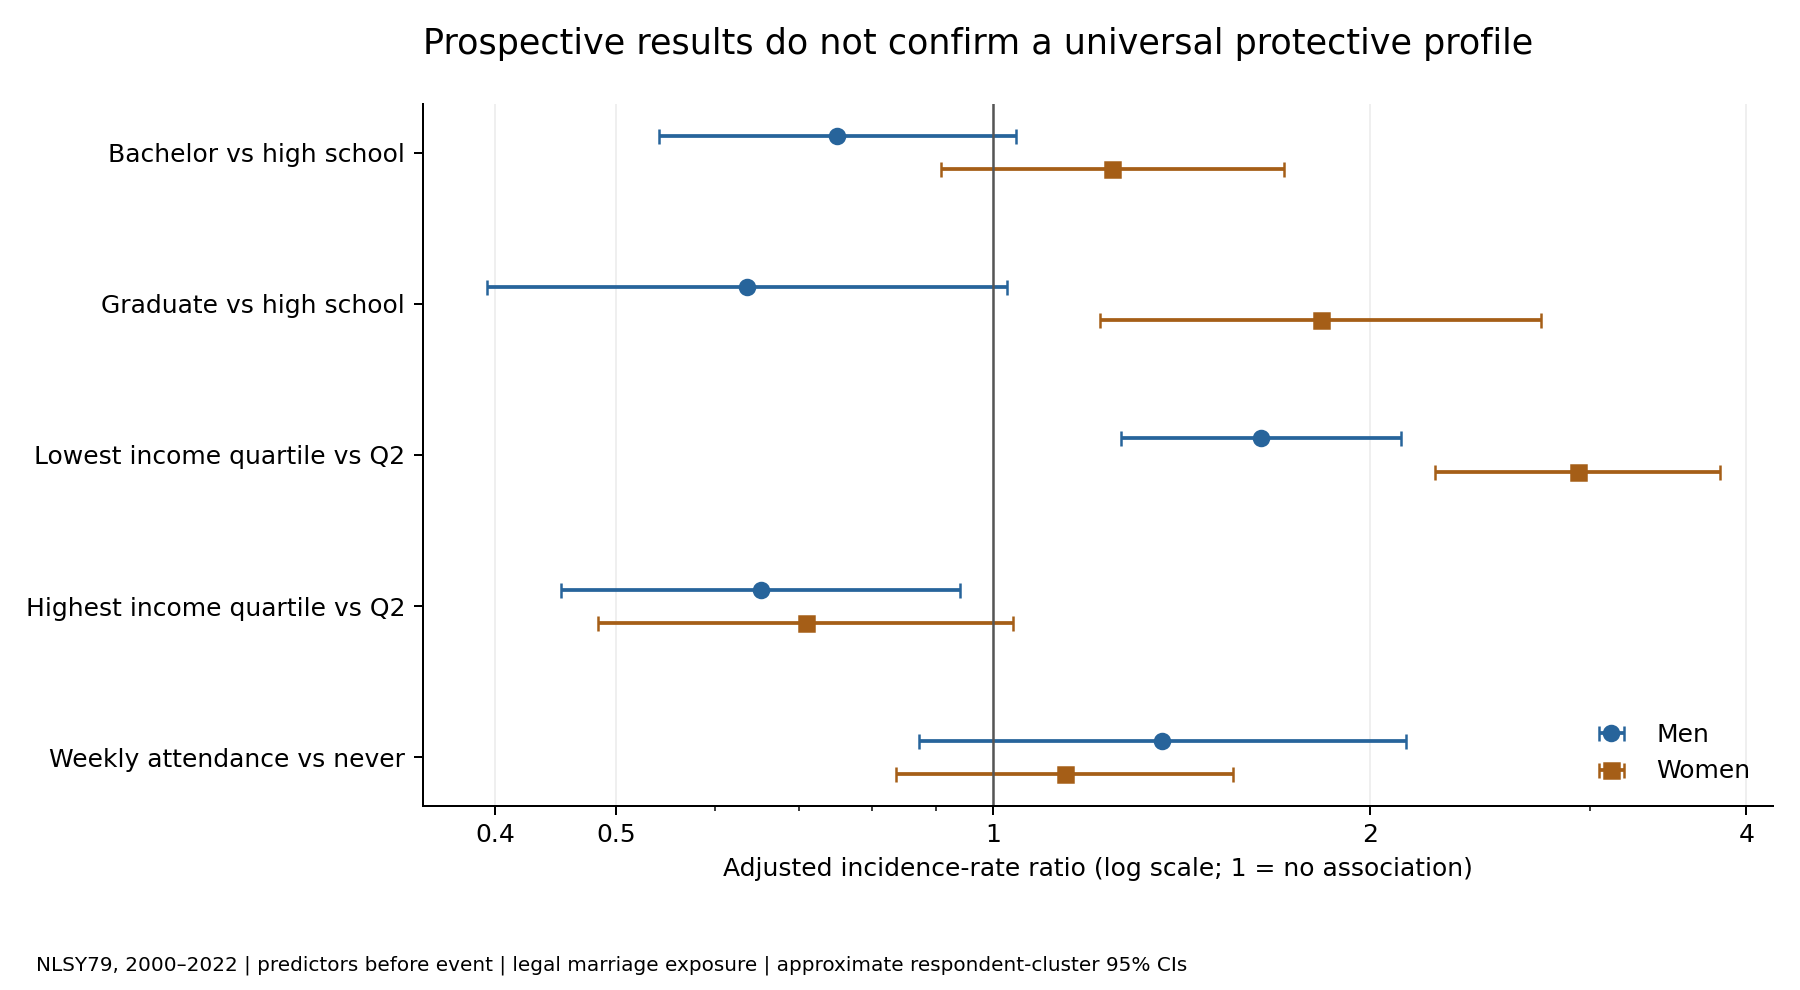

In [4]:
display(prospective[prospective.term.str.contains('education|income|religion')].round(3))
display(Image(filename=str(ROOT.parent/'figures/prospective_rate_ratios.png')))


## Independent computation checks

Refit the first-marriage full-weight ACS coefficients with an independent optimizer and independently recalculate the profile margins. Verify NLSY crude incidence from the saved interval data. Full replicate fitting and extraction are available through `run_annual.sh`.


In [5]:
_ = runpy.run_path(str(ROOT/'annual_acs/independent_check.py'),run_name='__main__')
# The NLSY checker independently recomputes the primary saved interval rates.
_ = runpy.run_path(str(ROOT/'annual_nlsy/verify_annual_nlsy.py'),run_name='__main__')


[{'sex': 'Men', 'max_logodds_difference': 2.2221113837872508e-13, 'profile_margin_check': 'passed', 'n': 369235, 'events': 4379}, {'sex': 'Women', 'max_logodds_difference': 1.0765849700611341e-07, 'profile_margin_check': 'passed', 'n': 386283, 'events': 4888}]


{
  "All": {
    "independent_rate_per_1000": 14.309476932087295,
    "saved_rate": 14.309476932087293,
    "events": 1463,
    "unweighted_person_years": 91578.75000000001
  },
  "Men": {
    "independent_rate_per_1000": 14.238984471756021,
    "saved_rate": 14.238984471756025,
    "events": 714,
    "unweighted_person_years": 44620.250000000015
  },
  "Women": {
    "independent_rate_per_1000": 14.382939217107378,
    "saved_rate": 14.38293921710738,
    "events": 749,
    "unweighted_person_years": 46958.5
  },
  "checks": "Passed exposure, endpoint, independent crude-rate, full-rank, score, and fitted-count checks."
}


## Interpretation

The clearest recent ACS lower-rate male profile combines college education, employment and higher personal income. For women, the recent association favors college/graduate education and avoiding unemployment, but the prospective older-cohort data do not support a universal credential advantage or maximizing personal salary as an ideal.

Already-separated status is the strongest immediate prospective marker, largely because it identifies marriages already on a dissolution pathway. Low family resources predict later divorce; income and employment are associations, not established causes. Do not recommend leaving work or reducing income because a selected observed cell has a low fitted rate. Current shared attendance/spouse education effects require better prospective paired data to rank on the same annual basis.

Source URLs and hashes: `acs/manifest.json`, `longitudinal/source_manifest.json`, `nsfg/manifest.json`. Details: `annual_acs/METHODS.md`, `annual_nlsy/METHODS.md`, `annual_nsfg/feasibility.md`.
